# OPE 6 - Morphological Operations to Remove Bright Specks and Fill Dark Cracks

Design a sequence of morphological operations to remove small bright noise, fill narrow dark cracks and preserve the overall shape. (CO3, CO4)

Enrollment No: 92400133081

## 1. Load the images and convert them to binary images

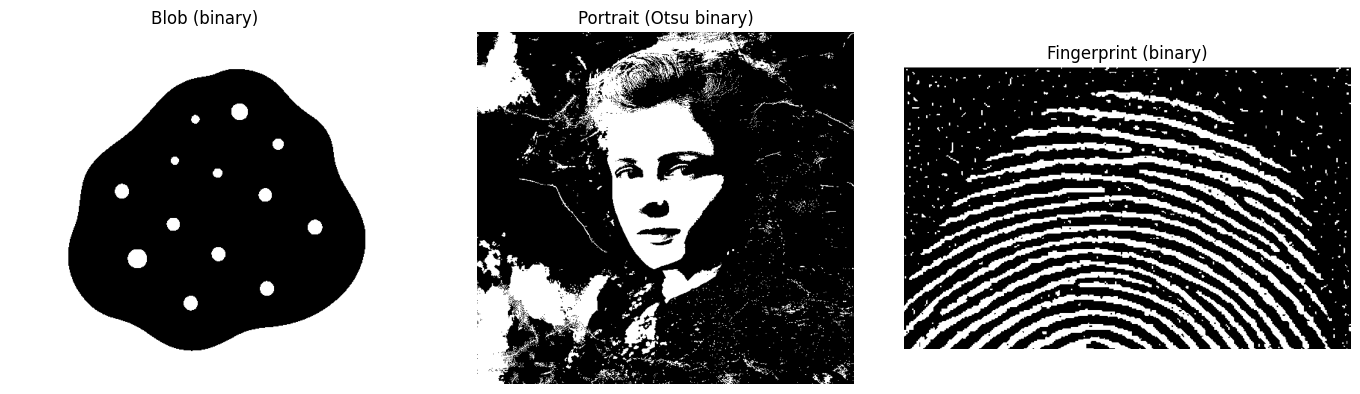

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Function to show images in a row
def show(images, titles, size=(14, 4)):
    plt.figure(figsize=size)
    for i in range(len(images)):
        plt.subplot(1, len(images), i + 1)
        plt.imshow(images[i], cmap='gray', vmin=0, vmax=255)
        plt.title(titles[i])
        plt.axis('off')
    plt.tight_layout()
    plt.show()

# Load the images as grayscale
blob_gray = cv2.imread('blob.png', 0)
portrait_gray = cv2.imread('portrait.png', 0)
finger_gray = cv2.imread('fingerprint.png', 0)

# Convert to binary images (white = 255 is the bright part)
_, blob = cv2.threshold(blob_gray, 127, 255, cv2.THRESH_BINARY)
_, finger = cv2.threshold(finger_gray, 127, 255, cv2.THRESH_BINARY)
_, portrait = cv2.threshold(portrait_gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

show([blob, portrait, finger], ['Blob (binary)', 'Portrait (Otsu binary)', 'Fingerprint (binary)'])

## 2. Measure the size of the specks, objects and cracks (to choose the structuring element)

In [2]:
# Blob : size of the bright specks inside the dark object
n, labels, stats, _ = cv2.connectedComponentsWithStats(blob, connectivity=8)
background = stats[1:, cv2.CC_STAT_AREA].argmax() + 1            # the largest white region is the background
sizes = [max(stats[i, cv2.CC_STAT_WIDTH], stats[i, cv2.CC_STAT_HEIGHT]) for i in range(1, n) if i != background]
print("Blob : number of bright specks =", len(sizes), ", largest speck =", max(sizes), "pixels")

# Fingerprint : lengths of white runs (ridges) and black runs (gaps) along vertical lines
def run_lengths(line):
    runs, value, count = [], line[0], 1
    for v in line[1:]:
        if v == value:
            count += 1
        else:
            runs.append((value, count))
            value, count = v, 1
    runs.append((value, count))
    return runs

white, black = [], []
for x in range(150, 450, 7):
    for value, length in run_lengths((finger[200:380, x] > 0).astype(int)):
        (white if value else black).append(length)

print("Fingerprint : median ridge width =", np.median(white), "pixels, median gap between ridges =", np.median(black), "pixels")
print("Fingerprint : white runs of 1-2 pixels =", sum(w <= 2 for w in white), ", black runs (cracks) of 1-2 pixels =", sum(b <= 2 for b in black))

n, labels, stats, _ = cv2.connectedComponentsWithStats(finger, connectivity=8)
speck = [max(stats[i, cv2.CC_STAT_WIDTH], stats[i, cv2.CC_STAT_HEIGHT]) for i in range(1, n) if stats[i, cv2.CC_STAT_AREA] <= 30]
print("Fingerprint : number of small bright specks =", len(speck), ", most of them are", np.bincount(speck).argmax(), "pixels wide")

Blob : number of bright specks = 13 , largest speck = 26 pixels
Fingerprint : median ridge width = 7.0 pixels, median gap between ridges = 12.0 pixels
Fingerprint : white runs of 1-2 pixels = 26 , black runs (cracks) of 1-2 pixels = 23
Fingerprint : number of small bright specks = 342 , most of them are 2 pixels wide


## 3. Sequence of operations

1. Closing (dilation followed by erosion) fills the narrow dark cracks. The structuring element must be wider than the cracks and smaller than the gaps between the objects.
2. Opening (erosion followed by dilation) removes the small bright specks. The structuring element must be larger than the largest speck and smaller than the thinnest part of the object.

The order (closing first, then opening) is chosen from the experiment in section 7: if opening is done first, it erodes the corners of the object at the ends of the cracks and the closing cannot restore them.

In [3]:
def clean_sequence(binary, close_se, open_se):
    closed = cv2.morphologyEx(binary, cv2.MORPH_CLOSE, close_se)    # fill narrow dark cracks
    opened = cv2.morphologyEx(closed, cv2.MORPH_OPEN, open_se)      # remove small bright specks
    return closed, opened

# Structuring elements
ellipse31 = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (31, 31))   # larger than the largest speck (26 pixels)
rect3 = np.ones((3, 3), np.uint8)                                    # larger than 1-2 pixel specks and cracks
cross3 = cv2.getStructuringElement(cv2.MORPH_CROSS, (3, 3))

## 4. Blob image (bright specks inside the dark object)

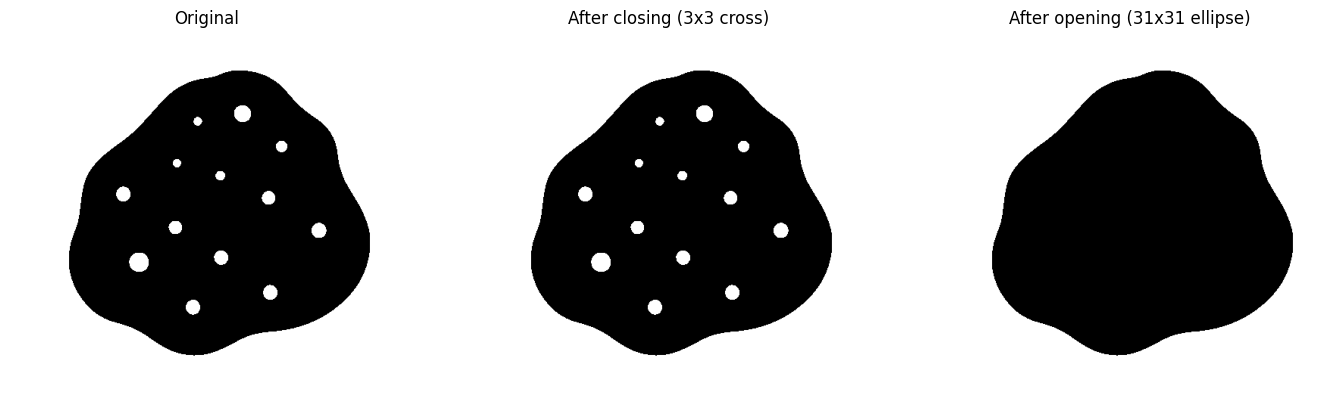

Specks (white) pixels inside the object : before = 3415 , after = 0
Shape match (IoU) of the dark object : before = 0.9683, after = 1.0000


In [4]:
closed, opened = clean_sequence(blob, cross3, ellipse31)
show([blob, closed, opened], ['Original', 'After closing (3x3 cross)', 'After opening (31x31 ellipse)'])

# Shape preservation : compare the dark object with the true object (object + specks)
n, labels, stats, _ = cv2.connectedComponentsWithStats(blob, connectivity=8)
background = stats[1:, cv2.CC_STAT_AREA].argmax() + 1
true_object = labels != background                         # dark object including the specks

def iou(a, b):
    return np.logical_and(a, b).sum() / np.logical_or(a, b).sum()

print("Specks (white) pixels inside the object : before =", int(np.sum((blob > 0) & true_object)), ", after =", int(np.sum((opened > 0) & true_object)))
print(f"Shape match (IoU) of the dark object : before = {iou(blob == 0, true_object):.4f}, after = {iou(opened == 0, true_object):.4f}")

## 5. Fingerprint image (bright specks in the background and dark cracks in the ridges)

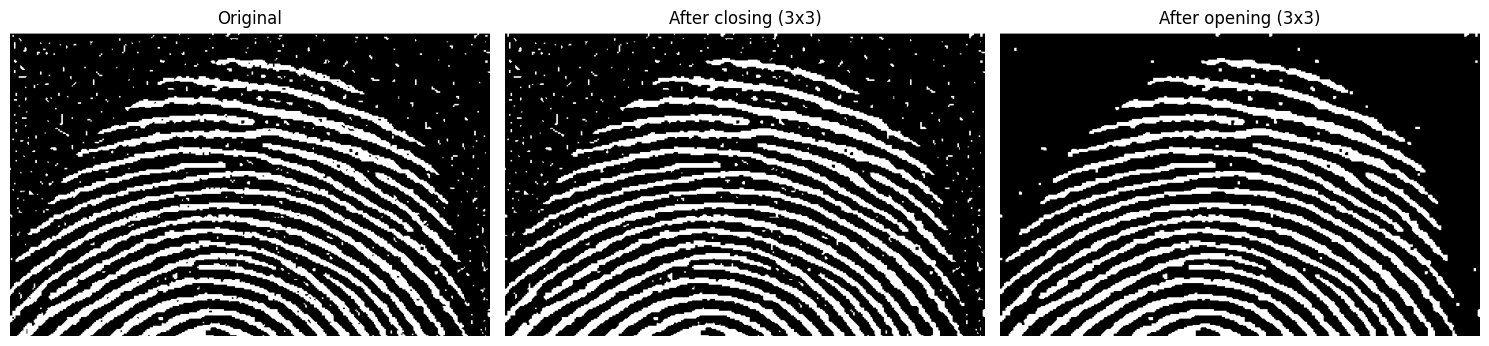

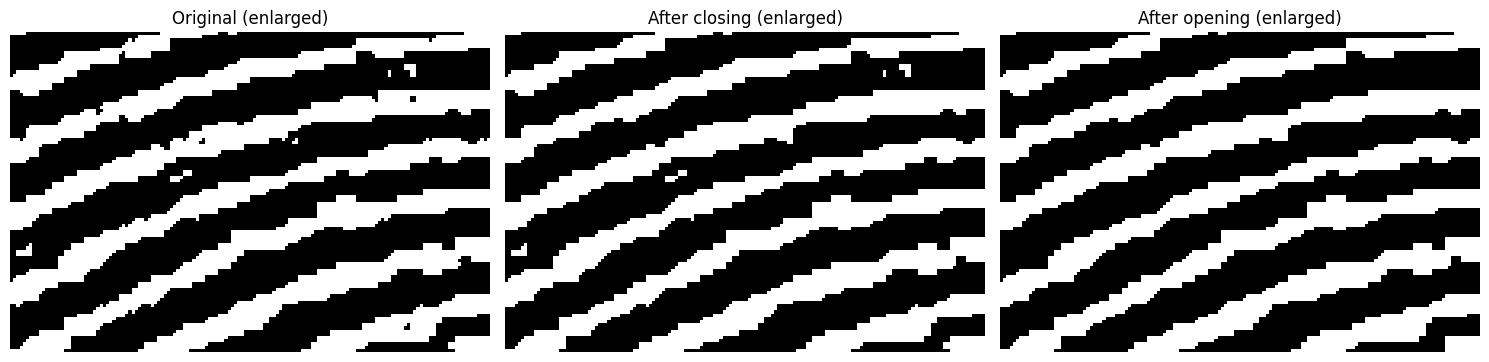

In [5]:
closed, opened = clean_sequence(finger, rect3, rect3)
show([finger, closed, opened], ['Original', 'After closing (3x3)', 'After opening (3x3)'], size=(15, 4))

# Enlarged part of the images
show([finger[200:300, 100:250], closed[200:300, 100:250], opened[200:300, 100:250]],
     ['Original (enlarged)', 'After closing (enlarged)', 'After opening (enlarged)'], size=(15, 4))

In [6]:
# Compare structuring elements and the order of operations on the fingerprint
def statistics(b):
    n, l, st, _ = cv2.connectedComponentsWithStats(b, connectivity=8)
    small = sum(1 for i in range(1, n) if st[i, cv2.CC_STAT_AREA] <= 30)                      # small bright specks
    large = [st[i, cv2.CC_STAT_AREA] for i in range(1, n) if st[i, cv2.CC_STAT_AREA] > 100]    # ridges
    n2, l2, st2, _ = cv2.connectedComponentsWithStats(255 - b, connectivity=8)
    cracks = sum(1 for i in range(1, n2) if st2[i, cv2.CC_STAT_AREA] <= 10)                    # small dark cracks
    return small, len(large), sum(large), cracks

ellipse5 = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))
op = lambda b, k: cv2.morphologyEx(b, cv2.MORPH_OPEN, k)
cl = lambda b, k: cv2.morphologyEx(b, cv2.MORPH_CLOSE, k)

methods = {
    'Original': finger,
    'Opening 3x3 only': op(finger, rect3),
    'Closing 3x3 only': cl(finger, rect3),
    'Closing -> Opening (3x3 square)': op(cl(finger, rect3), rect3),
    'Closing -> Opening (3x3 cross)': op(cl(finger, cross3), cross3),
    'Opening -> Closing (3x3 square)': cl(op(finger, rect3), rect3),
    'Closing -> Opening (5x5 ellipse)': op(cl(finger, ellipse5), ellipse5),
}

print(f"{'Method':34s}{'Specks':>8s}{'Ridges':>8s}{'Ridge area':>12s}{'Cracks':>8s}")
for name, b in methods.items():
    small, ridges, area, cracks = statistics(b)
    print(f"{name:34s}{small:8d}{ridges:8d}{area:12d}{cracks:8d}")

Method                              Specks  Ridges  Ridge area  Cracks
Original                               342      23       59084      41
Opening 3x3 only                        30      26       58390      18
Closing 3x3 only                       315      23       60083       0
Closing -> Opening (3x3 square)         35      23       59581       0
Closing -> Opening (3x3 cross)          91      23       60615       3
Opening -> Closing (3x3 square)         26      23       59007       0
Closing -> Opening (5x5 ellipse)        16      28       60178       0


## 6. Portrait image (not a binary image, so only an approximate result is possible)

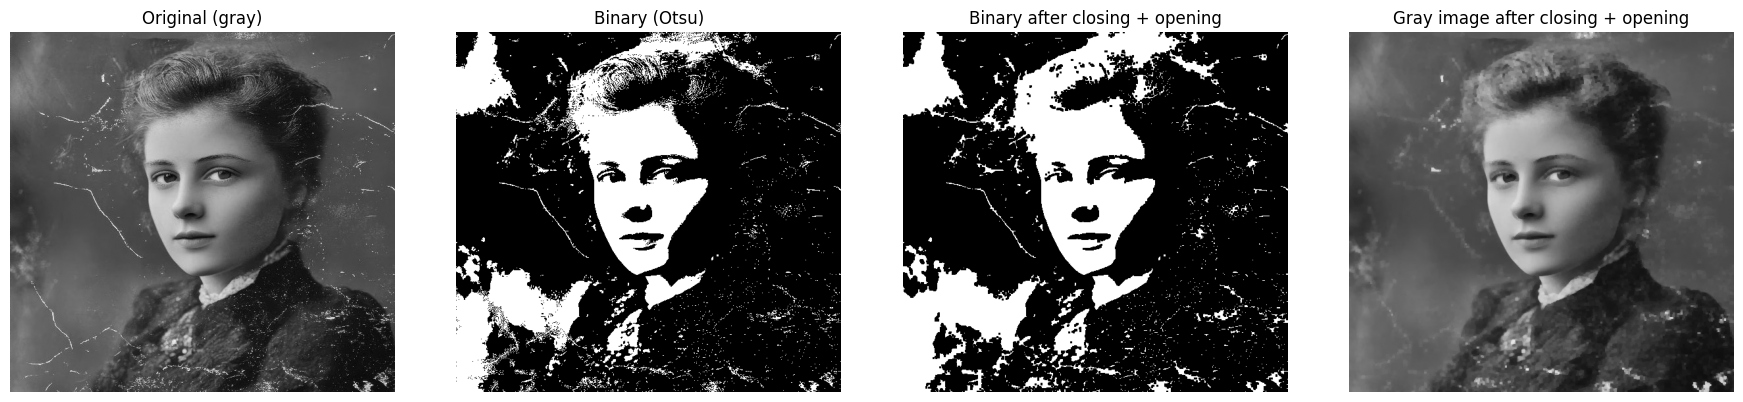

Small bright specks (<= 30 pixels) : before = 1964 , after = 83


In [7]:
# Binary version : same sequence with 3x3 structuring elements
closed, opened = clean_sequence(portrait, rect3, rect3)

# The same sequence directly on the gray image (gray scale closing and opening)
gray_closed = cv2.morphologyEx(portrait_gray, cv2.MORPH_CLOSE, rect3)
gray_result = cv2.morphologyEx(gray_closed, cv2.MORPH_OPEN, rect3)

show([portrait_gray, portrait, closed, gray_result],
     ['Original (gray)', 'Binary (Otsu)', 'Binary after closing + opening', 'Gray image after closing + opening'], size=(18, 4))
print("Small bright specks (<= 30 pixels) : before =", statistics(portrait)[0], ", after =", statistics(opened)[0])

## 7. Controlled experiment (a clean image with known specks and cracks)

A clean ridge pattern similar to the fingerprint (ridge width 7, gap 11 pixels) is made. Bright specks (1 to 4 pixels) and dark cracks (1 to 2 pixels wide) are added, and the result of every sequence is compared with the clean image. The number of wrong pixels is averaged over 20 random noisy images.

Method                              Specks only  Cracks only      Both  Both (%)
No filtering                                459          814      1229      1.37
Opening 3x3 only                            349         1113      1384      1.54
Closing 3x3 only                            616          517      1063      1.18
Closing -> Opening (3x3 square)             504          636      1037      1.15
Opening -> Closing (3x3 square)             430          960      1273      1.41
Closing -> Opening (3x3 cross)              422          773      1128      1.25
Closing -> Opening (5x5 ellipse)            525          276       708      0.79
Closing -> Opening (7x7 ellipse)            922          273      1047      1.16


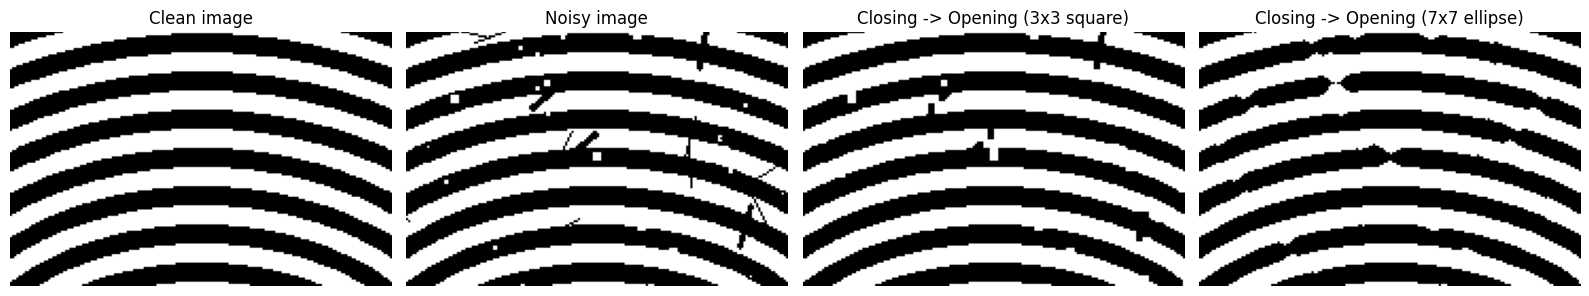

In [8]:
# Clean ridge pattern
clean = np.zeros((300, 300), np.uint8)
for r in range(30, 280, 18):
    cv2.ellipse(clean, (150, 290), (r + 40, r), 0, 180, 360, 255, 7)

# Add 130 bright specks (1 to 4 pixels)
def add_specks(img, rng):
    out = img.copy()
    for _ in range(130):
        x, y = rng.integers(5, 290, 2)
        s = rng.choice([1, 2, 2, 2, 3, 4])
        out[y:y + s, x:x + s] = 255
    return out

# Add 40 dark cracks (1 to 2 pixels wide) across the ridges
def add_cracks(img, rng):
    out = img.copy()
    for _ in range(40):
        x, y = rng.integers(20, 280, 2)
        angle = rng.uniform(0, np.pi)
        dx, dy = 10 * np.cos(angle), 10 * np.sin(angle)
        cv2.line(out, (int(x - dx), int(y - dy)), (int(x + dx), int(y + dy)), 0, int(rng.integers(1, 3)))
    return out

ellipse7 = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7, 7))
sequences = {
    'No filtering': lambda b: b,
    'Opening 3x3 only': lambda b: op(b, rect3),
    'Closing 3x3 only': lambda b: cl(b, rect3),
    'Closing -> Opening (3x3 square)': lambda b: op(cl(b, rect3), rect3),
    'Opening -> Closing (3x3 square)': lambda b: cl(op(b, rect3), rect3),
    'Closing -> Opening (3x3 cross)': lambda b: op(cl(b, cross3), cross3),
    'Closing -> Opening (5x5 ellipse)': lambda b: op(cl(b, ellipse5), ellipse5),
    'Closing -> Opening (7x7 ellipse)': lambda b: op(cl(b, ellipse7), ellipse7),
}

# Number of wrong pixels compared with the clean image (average of 20 images)
def wrong(b):
    return np.sum((b > 0) != (clean > 0))

results = {name: [[], [], []] for name in sequences}
for seed in range(20):
    rng = np.random.default_rng(seed)
    only_specks = add_specks(clean, rng)
    only_cracks = add_cracks(clean, rng)
    both = add_cracks(add_specks(clean, rng), rng)
    for name, f in sequences.items():
        results[name][0].append(wrong(f(only_specks)))
        results[name][1].append(wrong(f(only_cracks)))
        results[name][2].append(wrong(f(both)))

print(f"{'Method':34s}{'Specks only':>13s}{'Cracks only':>13s}{'Both':>10s}{'Both (%)':>10s}")
for name, r in results.items():
    print(f"{name:34s}{np.mean(r[0]):13.0f}{np.mean(r[1]):13.0f}{np.mean(r[2]):10.0f}{100 * np.mean(r[2]) / clean.size:10.2f}")

# Example result (enlarged part of the image)
rng = np.random.default_rng(0)
noisy = add_cracks(add_specks(clean, rng), rng)
crop = (slice(120, 240), slice(60, 240))
show([clean[crop], noisy[crop], sequences['Closing -> Opening (3x3 square)'](noisy)[crop], sequences['Closing -> Opening (7x7 ellipse)'](noisy)[crop]],
     ['Clean image', 'Noisy image', 'Closing -> Opening (3x3 square)', 'Closing -> Opening (7x7 ellipse)'], size=(16, 4))